# Care Load Intelligence — Notebook 03: Backtesting & Error Analysis
### 45-Origin Rolling Walk-Forward Validation & Horizon Error Sensitivity
**Author:** Utkarsh Sengar | **Live App:** https://cli-utkaresh-sengar-updated.streamlit.app/

---
## Overview
In operational practice, time-series models are re-estimated as new records arrive. Here we execute a rolling walk-forward backtest across 45 origins with a 7-step forecast horizon, demonstrating why Holt Damped wins short horizons.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, mean_squared_error

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

current_dir = Path(".").resolve()
REPO_ROOT = current_dir if (current_dir / "data").exists() else current_dir.parent

proc_path = REPO_ROOT / "data" / "processed" / "uac_observed_forecasting_data.csv"
df = pd.read_csv(proc_path)
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True)
target = "Children in HHS Care"

INIT_TRAIN = 400
HORIZON = 7
STEP = 7
series = df[target].astype(float)
origins = range(INIT_TRAIN, len(df) - HORIZON + 1, STEP)

records = []
for orig in origins:
    hist = series.iloc[:orig]
    acts = series.iloc[orig : orig + HORIZON].values
    
    # Naive
    p_naive = np.repeat(hist.iloc[-1], HORIZON)
    # ARIMA
    try:
        p_arima = np.maximum(ARIMA(hist, order=(1,1,1)).fit().forecast(steps=HORIZON).values, 0)
    except:
        p_arima = p_naive
    # Holt Damped
    try:
        p_hd = np.maximum(ExponentialSmoothing(hist, trend="add", damped_trend=True).fit(optimized=True).forecast(steps=HORIZON).values, 0)
    except:
        p_hd = p_naive
        
    for h in range(HORIZON):
        records.append({
            'Origin': orig,
            'Step': h + 1,
            'Actual': acts[h],
            'Naive': p_naive[h],
            'ARIMA_1_1_1': p_arima[h],
            'Holt_Damped': p_hd[h]
        })

wf_df = pd.DataFrame(records)
print(f"Generated {len(wf_df)} backtest predictions across {len(origins)} origins.")

Generated 315 backtest predictions across 45 origins.


## 1. Walk-Forward Metric Comparison

In [2]:
wf_res = []
for m in ['Holt_Damped', 'ARIMA_1_1_1', 'Naive']:
    mae = mean_absolute_error(wf_df['Actual'], wf_df[m])
    rmse = np.sqrt(mean_squared_error(wf_df['Actual'], wf_df[m]))
    wf_res.append({'Model': m, 'MAE': mae, 'RMSE': rmse})

display(pd.DataFrame(wf_res).sort_values('MAE').reset_index(drop=True))

,Model,MAE,RMSE
0,Holt_Damped,78.919878,160.868431
1,ARIMA_1_1_1,99.022776,191.671071
2,Naive,102.612698,197.623267


## 2. Error Degradation by Horizon Step

C:\Users\utkar\AppData\Local\Temp\ipykernel_129220\1528428472.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  step_df = wf_df.groupby('Step').apply(lambda g: pd.Series({


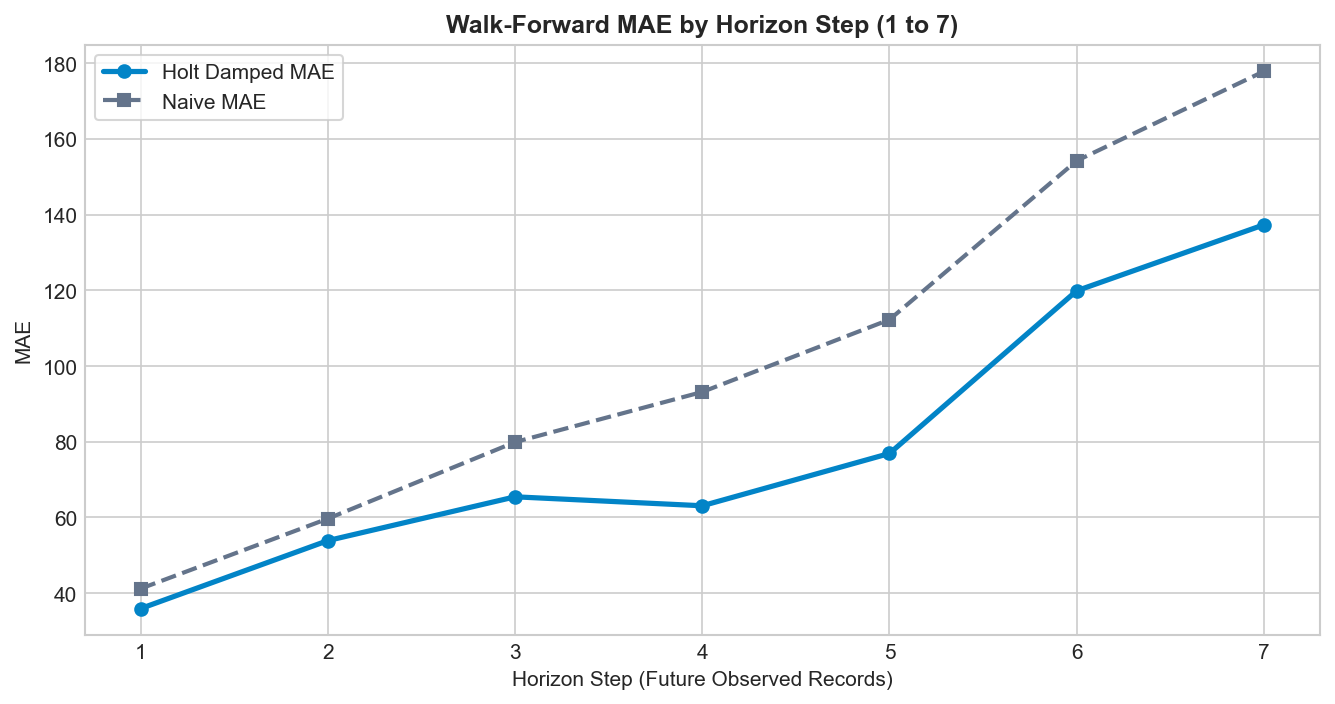

In [3]:
step_df = wf_df.groupby('Step').apply(lambda g: pd.Series({
    'MAE_Holt_Damped': mean_absolute_error(g['Actual'], g['Holt_Damped']),
    'MAE_Naive': mean_absolute_error(g['Actual'], g['Naive'])
})).reset_index()

fig, ax = plt.subplots(figsize=(9, 4.8), dpi=150)
ax.plot(step_df['Step'], step_df['MAE_Holt_Damped'], marker='o', color='#0284c7', linewidth=2.5, label='Holt Damped MAE')
ax.plot(step_df['Step'], step_df['MAE_Naive'], marker='s', color='#64748b', linewidth=2.0, linestyle='--', label='Naive MAE')
ax.set_title("Walk-Forward MAE by Horizon Step (1 to 7)", fontsize=12, fontweight='bold')
ax.set_xlabel("Horizon Step (Future Observed Records)")
ax.set_ylabel("MAE")
ax.legend(frameon=True)
plt.tight_layout()
plt.show()